Tehtävä 16
Kirjoita Fourier-muunnokseen perustuvat yli- ja alipäästösuodattimet. Anna funktioille parametreina signaali, näytteenottoväli ja rajataajuus.

a) Testaa suodattimia tunnetulla summasignaalilla.

b) Testaa niitä kävelymittaukseen.

c) Vertaa tuloksia tehtävässä 11 käyttämääsi suodatukseen.

Toimii hyvin



In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def lowpass_filter(signal, dt, cutoff):
    N = len(signal)

    fourier = np.fft.fft(signal)
    freq = np.fft.fftfreq(N, dt)

    # Poistetaan rajataajuutta korkeammat taajuudet
    fourier[np.abs(freq) > cutoff] = 0

    filtered = np.fft.ifft(fourier).real

    return filtered


def highpass_filter(signal, dt, cutoff):
    N = len(signal)

    fourier = np.fft.fft(signal)
    freq = np.fft.fftfreq(N, dt)

    # Poistetaan rajataajuutta matalammat taajuudet
    fourier[np.abs(freq) < cutoff] = 0

    filtered = np.fft.ifft(fourier).real

    return filtered

C:\Users\tommi\AppData\Local\Temp\ipykernel_5696\330976999.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


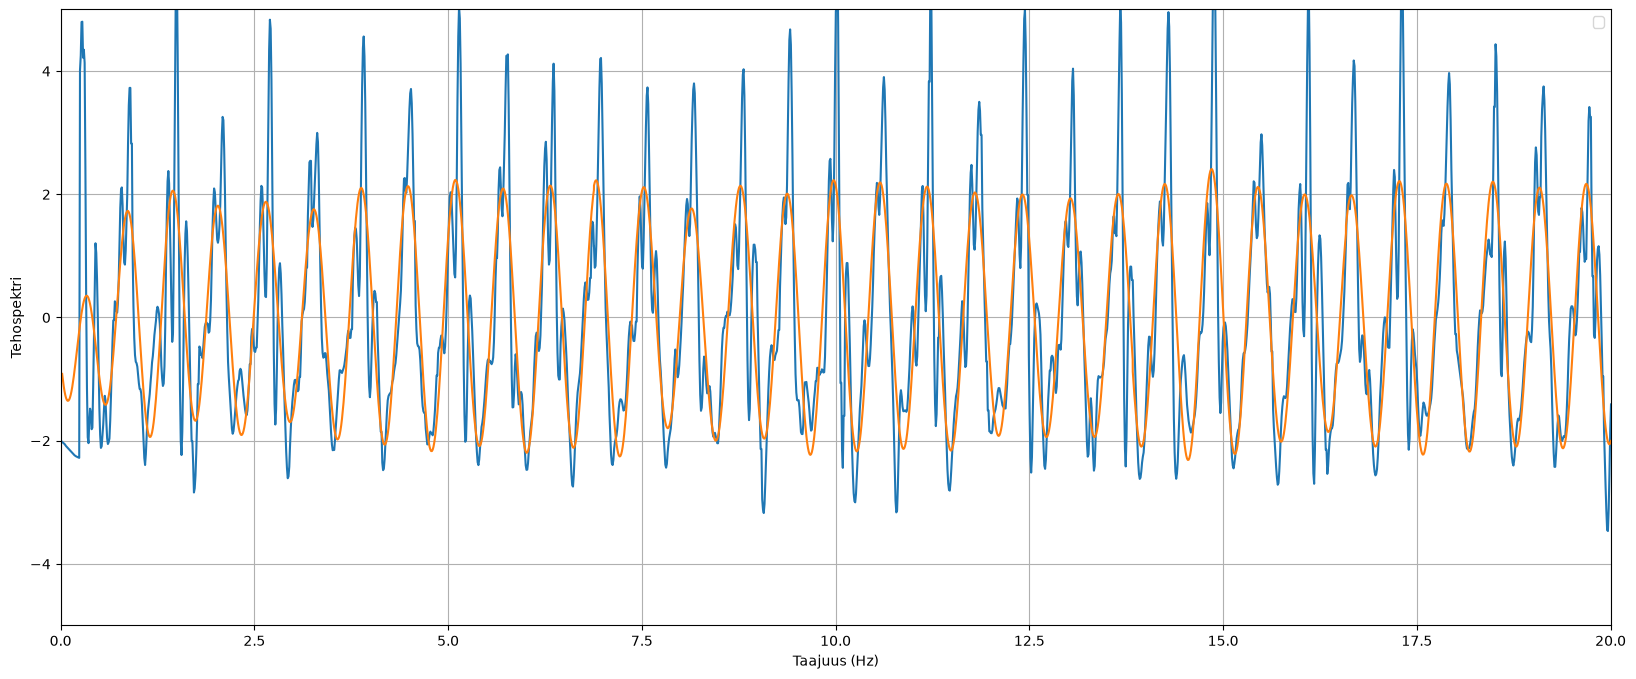

In [20]:
df = pd.read_csv('./Data/Acceleration_withoutG/walkingData.csv')
t = df['Time (s)']
z_signal = df['Linear Acceleration z (m/s^2)']
N = len(t)
dt = np.median(np.diff(t))
cutoff = 1/0.5

filtered = lowpass_filter(z_signal, dt, cutoff)
#filtered = highpass_filter(z_signal, dt, cutoff)

plt.figure(figsize=(20,8))
plt.plot(t, z_signal)
plt.plot(t, filtered)
plt.xlabel("Taajuus (Hz)")
plt.ylabel("Tehospektri")
#plt.axhline(100, color="red", linestyle="--", label="Suodatusraja")
plt.legend()
plt.grid()
plt.axis([0,20,-5,5])
plt.show()